Compuerta (00)  (01)  (10)  (11)  Épocas    Convergió   Pesos / Bias
-----------------------------------------------------------------------------------------------
AND       0     0     0     1     4         Sí          w=[0.2 0.1], b=-0.2
OR        0     1     1     1     4         Sí          w=[0.1 0.1], b=-0.1
XOR       1     1     0     0     50        No          w=[-0.1  0. ], b=0.0


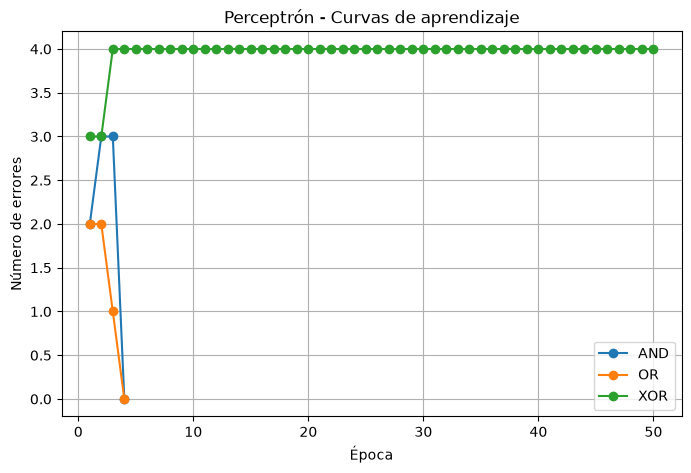

In [40]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)


X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_AND = np.array([0, 0, 0, 1])
y_OR  = np.array([0, 1, 1, 1])
y_XOR = np.array([0, 1, 1, 0])

compuertas = {
    "AND": y_AND,
    "OR": y_OR,
    "XOR": y_XOR
}



def escalon(z):
    return 1 if z >= 0 else 0


def entrena_perceptron(X, y, eta=0.1, T=50):
    w = np.zeros(X.shape[1])
    b = 0.0
    historial = []

    for epoca in range(T):
        errores = 0

        for x, respuesta_correcta in zip(X, y):
            z = np.dot(w, x) + b
            prediccion = escalon(z)

            error = respuesta_correcta - prediccion

            w += eta * error * x
            b += eta * error

            errores += abs(error)

        historial.append(int(errores))

        if errores == 0:
            break

    return w, b, historial


def predice_perceptron(X, w, b):
    predicciones = []

    for x in X:
        z = np.dot(w, x) + b
        predicciones.append(escalon(z))

    return np.array(predicciones)



eta = 0.1
T = 50

resultados_p1 = {}

for nombre, y in compuertas.items():
    w, b, historial = entrena_perceptron(
        X, y, eta=eta, T=T
    )

    predicciones = predice_perceptron(X, w, b)

    resultados_p1[nombre] = {
        "w": w,
        "b": b,
        "historial": historial,
        "predicciones": predicciones,
        "convergio": historial[-1] == 0
    }



print(
    f"{'Compuerta':<10}"
    f"{'(00)':<6}"
    f"{'(01)':<6}"
    f"{'(10)':<6}"
    f"{'(11)':<6}"
    f"{'Épocas':<10}"
    f"{'Convergió':<12}"
    f"{'Pesos / Bias'}"
)

print("-" * 95)

for nombre, r in resultados_p1.items():
    p = r["predicciones"]

    print(
        f"{nombre:<10}"
        f"{p[0]:<6}"
        f"{p[1]:<6}"
        f"{p[2]:<6}"
        f"{p[3]:<6}"
        f"{len(r['historial']):<10}"
        f"{('Sí' if r['convergio'] else 'No'):<12}"
        f"w={np.round(r['w'], 3)}, b={round(r['b'], 3)}"
    )



plt.figure(figsize=(8, 5))

for nombre, r in resultados_p1.items():
    historial = r["historial"]

    plt.plot(
        range(1, len(historial) + 1),
        historial,
        marker="o",
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Número de errores")
plt.title("Perceptrón - Curvas de aprendizaje")
plt.legend()
plt.grid()
plt.show()

### P1. Análisis del Perceptrón y de XOR

En los resultados, AND y OR clasifican correctamente las cuatro entradas y convergen en 4 épocas. XOR llega al límite de 50 épocas sin converger, con predicciones `[1, 1, 0, 0]` frente a las etiquetas `[0, 1, 1, 0]`.

AND y OR son linealmente separables: una recta puede separar sus dos clases. En XOR, los puntos de la clase 1 están en dos esquinas opuestas y los de la clase 0 en las otras dos. Una única recta no puede separar esas clases. Por ello, la curva de errores del Perceptrón no se estabiliza en cero; aumentar el número de épocas no elimina esta limitación del modelo.


Compuerta (00)  (01)  (10)  (11)  J final     Clasif.     4/4     Pesos / Bias
---------------------------------------------------------------------------------------------------------
AND       0     0     0     1     0.042306    192         Sí      w=[0.297 0.297], b=-0.009
OR        0     1     1     1     0.034506    65          Sí      w=[0.389 0.389], b=0.38
XOR       0     0     0     1     0.127314    Nunca       No      w=[0.093 0.093], b=0.389


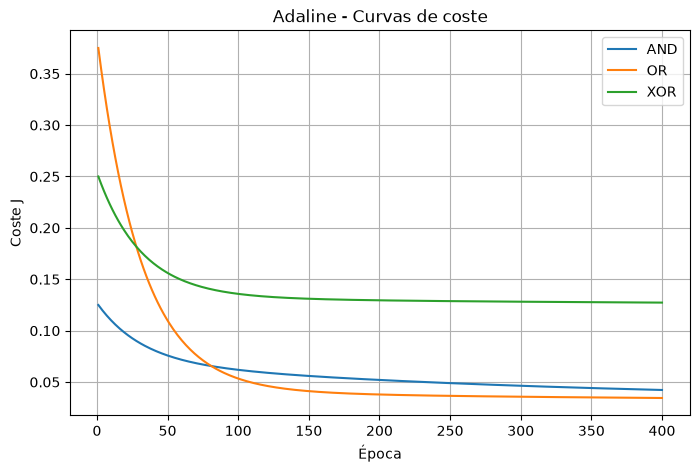

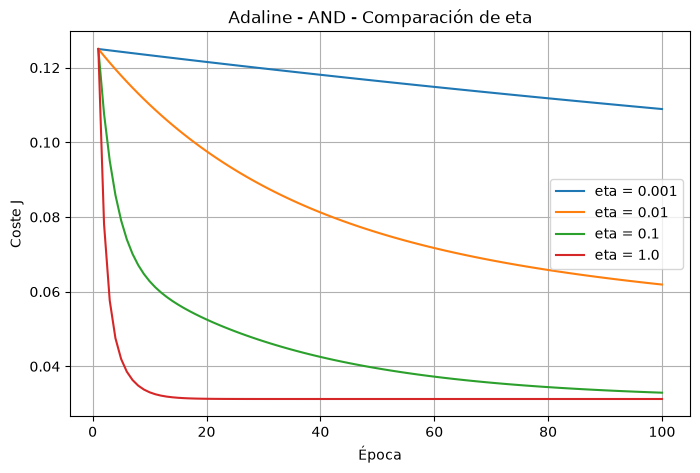

In [41]:

def entrena_adaline(X, y, eta=0.01, T=400):
    N = len(X)

    w = np.zeros(X.shape[1])
    b = 0.0
    historial = []

    epoca_clasificacion_correcta = None

    for epoca in range(T):
        z = X @ w + b

        e = y - z

        # Coste antes de actualizar
        J = (e**2).sum() / (2 * N)
        historial.append(J)

        predicciones = np.where(z >= 0.5, 1, 0)

        if (
            epoca_clasificacion_correcta is None
            and np.array_equal(predicciones, y)
        ):
            epoca_clasificacion_correcta = epoca + 1

        w += eta * (X.T @ e) / N
        b += eta * e.sum() / N

    return w, b, historial, epoca_clasificacion_correcta


def predice_adaline(X, w, b):
    z = X @ w + b
    return np.where(z >= 0.5, 1, 0)



eta = 0.01
T = 400

resultados_p2 = {}

for nombre, y in compuertas.items():
    w, b, historial, epoca_clasif = entrena_adaline(
        X, y, eta=eta, T=T
    )

    predicciones = predice_adaline(X, w, b)

    resultados_p2[nombre] = {
        "w": w,
        "b": b,
        "historial": historial,
        "predicciones": predicciones,
        "J_final": historial[-1],
        "epoca_clasif": epoca_clasif,
        "clasifica_bien": np.array_equal(predicciones, y)
    }



print(
    f"{'Compuerta':<10}"
    f"{'(00)':<6}"
    f"{'(01)':<6}"
    f"{'(10)':<6}"
    f"{'(11)':<6}"
    f"{'J final':<12}"
    f"{'Clasif.':<12}"
    f"{'4/4':<8}"
    f"{'Pesos / Bias'}"
)

print("-" * 105)

for nombre, r in resultados_p2.items():
    p = r["predicciones"]

    epoca = (
        str(r["epoca_clasif"])
        if r["epoca_clasif"] is not None
        else "Nunca"
    )

    print(
        f"{nombre:<10}"
        f"{p[0]:<6}"
        f"{p[1]:<6}"
        f"{p[2]:<6}"
        f"{p[3]:<6}"
        f"{r['J_final']:<12.6f}"
        f"{epoca:<12}"
        f"{('Sí' if r['clasifica_bien'] else 'No'):<8}"
        f"w={np.round(r['w'], 3)}, b={round(r['b'], 3)}"
    )



plt.figure(figsize=(8, 5))

for nombre, r in resultados_p2.items():
    plt.plot(
        range(1, len(r["historial"]) + 1),
        r["historial"],
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Coste J")
plt.title("Adaline - Curvas de coste")
plt.legend()
plt.grid()
plt.show()



etas = [0.001, 0.01, 0.1, 1.0]

plt.figure(figsize=(8, 5))

for eta_prueba in etas:
    w, b, historial, _ = entrena_adaline(
        X,
        y_AND,
        eta=eta_prueba,
        T=100
    )

    plt.plot(
        range(1, len(historial) + 1),
        historial,
        label=f"eta = {eta_prueba}"
    )

plt.xlabel("Época")
plt.ylabel("Coste J")
plt.title("Adaline - AND - Comparación de eta")
plt.legend()
plt.grid()
plt.show()

### P2. Análisis de Adaline: tasa de aprendizaje y XOR

Adaline ajusta una salida continua mediante descenso de gradiente y aplica el umbral 0.5 para clasificar. El coste cuadrático mide la diferencia entre las salidas continuas y las etiquetas; clasificar las cuatro entradas correctamente no implica que ese coste sea cero.

Con una tasa de aprendizaje `eta` demasiado pequeña, las actualizaciones son pequeñas y el coste disminuye lentamente: pueden necesitarse muchas más épocas. Con una tasa demasiado grande, las actualizaciones pueden sobrepasar el mínimo, provocar oscilaciones o hacer que el coste crezca y el entrenamiento diverja. Una curva descendente que se estabiliza permite valorar la convergencia. El cuaderno incluye una comparación experimental de cuatro tasas de aprendizaje para AND.

Para XOR, el coste permanece positivo porque la salida de Adaline es una función lineal y no puede representar esta compuerta. Con las cuatro entradas equilibradas, la mejor aproximación cuadrática es una salida constante de 0.5, cuyo coste mínimo es `J = 0.125` con la definición utilizada. Estancarse cerca de ese valor refleja una limitación de representación del modelo, aunque el descenso de gradiente converja.

En esta ejecución (400 épocas), AND alcanza las cuatro clasificaciones correctas en la época 192 y OR en la 65. Sus costes finales son 0.042306 y 0.034506. XOR nunca clasifica las cuatro entradas correctamente y termina con un coste de 0.127314, próximo al mínimo teórico positivo.


Compuerta Error   J final     J<0.01      Clasif.     4/4     Salidas finales
----------------------------------------------------------------------------------------------------
AND       MSE     0.024850    >500        109         Sí      [0.038  0.2361 0.2361 0.7076]
AND       CE      0.066880    >500        34          Sí      [8.00e-04 7.47e-02 7.47e-02 8.95e-01]
OR        MSE     0.015180    >500        121         Sí      [0.2693 0.8442 0.8442 0.9876]
OR        CE      0.037868    >500        40          Sí      [0.0817 0.9676 0.9676 0.9999]
XOR       MSE     0.125000    >500        Nunca       No      [0.5 0.5 0.5 0.5]
XOR       CE      0.693147    >500        Nunca       No      [0.5 0.5 0.5 0.5]


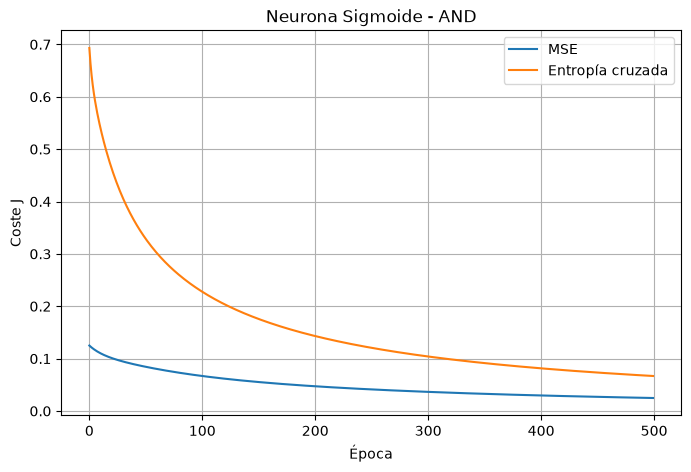

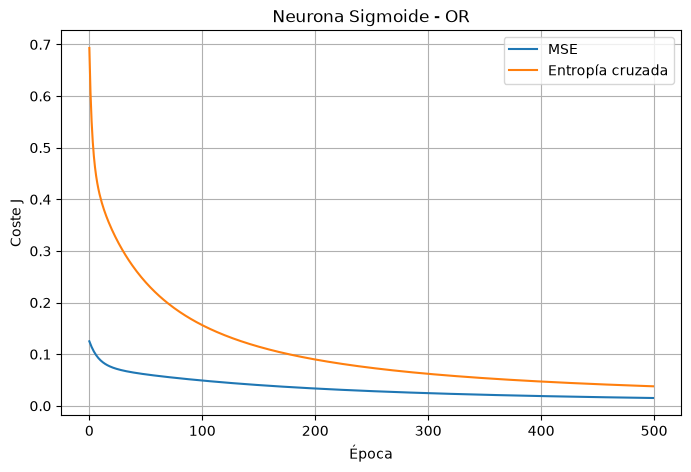

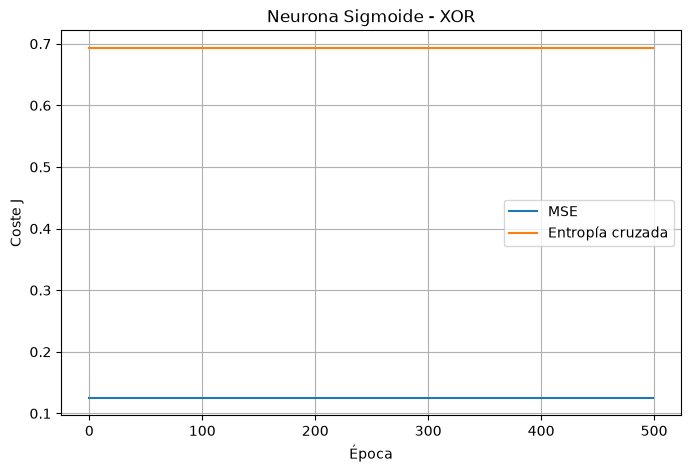

In [42]:

def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-z))


def entrena_sigmoide(X, y, eta=0.5, T=500, tipo="CE"):
    N = len(X)

    w = np.zeros(X.shape[1])
    b = 0.0

    historial = []

    epoca_clasificacion_correcta = None
    epoca_error_001 = None

    # Evita log(0) en entropía cruzada
    eps = 1e-9

    for epoca in range(T):
        z = X @ w + b
        yhat = sigmoide(z)

        predicciones = np.where(
            yhat >= 0.5,
            1,
            0
        )

        # Primera época con las cuatro clasificaciones correctas
        if (
            epoca_clasificacion_correcta is None
            and np.array_equal(predicciones, y)
        ):
            epoca_clasificacion_correcta = epoca + 1

        e = y - yhat

        if tipo == "CE":
            g = e

            J = -np.mean(
                y * np.log(yhat + eps)
                + (1 - y) * np.log(1 - yhat + eps)
            )

        else:
            g = e * yhat * (1 - yhat)

            J = np.mean(e**2) / 2

        # Primera época donde J < 0.01
        if (
            epoca_error_001 is None
            and J < 0.01
        ):
            epoca_error_001 = epoca + 1

        w += eta * (X.T @ g) / N
        b += eta * g.sum() / N

        historial.append(J)

    return (
        w,
        b,
        historial,
        epoca_clasificacion_correcta,
        epoca_error_001
    )


def predice_sigmoide(X, w, b):
    probabilidades = sigmoide(X @ w + b)

    predicciones = np.where(
        probabilidades >= 0.5,
        1,
        0
    )

    return probabilidades, predicciones



eta = 0.5
T = 500

tipos_error = ["MSE", "CE"]

resultados_p3 = []

for nombre, y in compuertas.items():

    for tipo in tipos_error:

        (
            w,
            b,
            historial,
            epoca_clasif,
            epoca_001
        ) = entrena_sigmoide(
            X,
            y,
            eta=eta,
            T=T,
            tipo=tipo
        )

        probabilidades, predicciones = predice_sigmoide(
            X,
            w,
            b
        )

        resultados_p3.append({
            "compuerta": nombre,
            "error": tipo,
            "w": w,
            "b": b,
            "historial": historial,
            "J_final": historial[-1],
            "epoca_001": epoca_001,
            "epoca_clasif": epoca_clasif,
            "clasifica_bien": np.array_equal(
                predicciones,
                y
            ),
            "salidas": probabilidades,
            "predicciones": predicciones
        })



print(
    f"{'Compuerta':<10}"
    f"{'Error':<8}"
    f"{'J final':<12}"
    f"{'J<0.01':<12}"
    f"{'Clasif.':<12}"
    f"{'4/4':<8}"
    f"Salidas finales"
)

print("-" * 100)

for r in resultados_p3:

    epoca_001 = (
        str(r["epoca_001"])
        if r["epoca_001"] is not None
        else f">{T}"
    )

    epoca_clasif = (
        str(r["epoca_clasif"])
        if r["epoca_clasif"] is not None
        else "Nunca"
    )

    bien = (
        "Sí"
        if r["clasifica_bien"]
        else "No"
    )

    salidas = np.round(
        r["salidas"],
        4
    )

    print(
        f"{r['compuerta']:<10}"
        f"{r['error']:<8}"
        f"{r['J_final']:<12.6f}"
        f"{epoca_001:<12}"
        f"{epoca_clasif:<12}"
        f"{bien:<8}"
        f"{salidas}"
    )



for nombre in compuertas:

    resultado_mse = next(
        r for r in resultados_p3
        if r["compuerta"] == nombre
        and r["error"] == "MSE"
    )

    resultado_ce = next(
        r for r in resultados_p3
        if r["compuerta"] == nombre
        and r["error"] == "CE"
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        resultado_mse["historial"],
        label="MSE"
    )

    plt.plot(
        resultado_ce["historial"],
        label="Entropía cruzada"
    )

    plt.xlabel("Época")
    plt.ylabel("Coste J")
    plt.title(f"Neurona Sigmoide - {nombre}")
    plt.legend()
    plt.grid()

    plt.show()

### P3. Comparación entre MSE y entropía cruzada (CE)

Con `eta = 0.5` y 500 épocas, CE alcanza por primera vez las cuatro clasificaciones correctas en la época 34 para AND y en la 40 para OR. MSE las alcanza en las épocas 109 y 121, respectivamente. Ambas pérdidas consiguen clasificar estas dos compuertas, pero CE lo hace antes y produce probabilidades finales más próximas a las etiquetas. Por estos criterios, CE ofrece mejores resultados en este experimento.

Las curvas muestran la evolución de cada función de coste. Sus valores finales no se comparan directamente para decidir cuál es mejor, porque MSE y CE tienen escalas y definiciones diferentes. Ninguna alcanza su propio umbral `J < 0.01` durante las 500 épocas, aunque AND y OR ya estén correctamente clasificadas.

**CE:** es adecuada para clasificación binaria y, combinada con la sigmoide, su gradiente evita el factor adicional `yhat * (1 - yhat)` de MSE. Esto favorece el aprendizaje cuando hay predicciones erróneas muy próximas a 0 o 1. Como desventaja, penaliza mucho los errores con alta confianza y exige cuidado numérico al calcular los logaritmos.

**MSE:** tiene una interpretación sencilla como error cuadrático y es útil para regresión. En esta clasificación aprende más despacio; su gradiente incluye la derivada de la sigmoide, que puede ser pequeña cuando la neurona se satura.

Para XOR, ambas pérdidas mantienen las salidas en 0.5 desde la inicialización simétrica utilizada y no consiguen las cuatro clasificaciones correctas. Los costes son 0.125 para MSE y aproximadamente 0.693147 para CE. Cambiar la pérdida no resuelve la falta de separabilidad lineal: una sola neurona sigmoide también tiene una frontera de decisión lineal.
